# Real-time Implementation and Automation with IBKR

--------------------------------------------------------------------------------------------------------------------

_Disclaimer: <br>
The following illustrative examples are for general information and educational purposes only. <br>
It is neither investment advice nor a recommendation to trade, invest or take whatsoever actions.<br>
The below code should only be used in combination with an IBKR Practice/Demo Account and NOT with a Live Trading Account._

------------------------------------------------------------------------------------

## IBKR API - Recap

__Update__: ib_insync has been migrated to __ib_async__. From now on, __please use ib_async:__

pip install ib_async

In [30]:
from ib_async import *
util.startLoop() 

In [31]:
ib = IB()

In [33]:
ib.connect()

<IB connected to 127.0.0.1:7497 clientId=1>

In [34]:
ib.positions()

[Position(account='DUM733929', contract=Stock(conId=4815747, symbol='NVDA', exchange='NASDAQ', currency='USD', localSymbol='NVDA', tradingClass='NMS'), position=100.0, avgCost=178.400022)]

In [35]:
contract = Forex('EURUSD')
contract

Forex('EURUSD', exchange='IDEALPRO')

In [36]:
ib.qualifyContracts(contract)

[Forex('EURUSD', conId=12087792, exchange='IDEALPRO', localSymbol='EUR.USD', tradingClass='EUR.USD')]

In [37]:
data = ib.reqMktData(contract) # subscribe to tick data
data

Ticker(contract=Forex('EURUSD', conId=12087792, exchange='IDEALPRO', localSymbol='EUR.USD', tradingClass='EUR.USD'), defaults=IBDefaults(emptyPrice=-1, emptySize=0, unset=nan, timezone=datetime.timezone.utc), created=True)

In [38]:
data

Ticker(contract=Forex('EURUSD', conId=12087792, exchange='IDEALPRO', localSymbol='EUR.USD', tradingClass='EUR.USD'), time=datetime.datetime(2026, 1, 28, 11, 26, 53, 93964, tzinfo=datetime.timezone.utc), timestamp=1769599613.0939717, minTick=1e-05, bid=1.19718, bidSize=1000000.0, ask=1.19719, askSize=1000000.0, last=1.1972, lastSize=0.0, lastTimestamp=datetime.datetime(2026, 1, 28, 11, 26, 35, tzinfo=datetime.timezone.utc), prevBid=1.19717, prevBidSize=2000000.0, prevAsk=1.1972, prevAskSize=6000000.0, volume=0.0, high=1.20455, low=1.1965, close=1.2041, halted=0, ticks=[TickData(time=datetime.datetime(2026, 1, 28, 11, 26, 53, 93964, tzinfo=datetime.timezone.utc), tickType=1, price=1.19718, size=1000000.0)], defaults=IBDefaults(emptyPrice=-1, emptySize=0, unset=nan, timezone=datetime.timezone.utc), created=True)

In [39]:
data.bid

1.19718

In [40]:
ib.cancelMktData(contract) # unsubscribe market data

True

In [41]:
ib.reqMktData(contract)

Ticker(contract=Forex('EURUSD', conId=12087792, exchange='IDEALPRO', localSymbol='EUR.USD', tradingClass='EUR.USD'), time=datetime.datetime(2026, 1, 28, 11, 26, 57, 751153, tzinfo=datetime.timezone.utc), timestamp=1769599617.7511604, minTick=1e-05, bid=1.19718, bidSize=1000000.0, ask=1.19719, askSize=1000000.0, last=1.1972, lastSize=0.0, lastTimestamp=datetime.datetime(2026, 1, 28, 11, 26, 35, tzinfo=datetime.timezone.utc), prevBid=1.19719, prevBidSize=2000000.0, prevAsk=1.1972, prevAskSize=2000000.0, volume=0.0, high=1.20455, low=1.1965, close=1.2041, halted=0, ticks=[TickData(time=datetime.datetime(2026, 1, 28, 11, 26, 57, 751153, tzinfo=datetime.timezone.utc), tickType=3, price=1.19719, size=1000000.0)], defaults=IBDefaults(emptyPrice=-1, emptySize=0, unset=nan, timezone=datetime.timezone.utc), created=True)

In [42]:
ticker = ib.ticker(contract)
ticker

Ticker(contract=Forex('EURUSD', conId=12087792, exchange='IDEALPRO', localSymbol='EUR.USD', tradingClass='EUR.USD'), time=datetime.datetime(2026, 1, 28, 11, 27, 5, 620868, tzinfo=datetime.timezone.utc), timestamp=1769599625.6208842, minTick=1e-05, bid=1.19719, bidSize=2000000.0, ask=1.19721, askSize=5000000.0, last=1.1972, lastSize=0.0, lastTimestamp=datetime.datetime(2026, 1, 28, 11, 27, 5, tzinfo=datetime.timezone.utc), prevBid=1.19718, prevBidSize=1000000.0, prevAsk=1.1972, prevAskSize=1000000.0, prevLast=1.1972, prevLastSize=0.0, volume=0.0, high=1.20455, low=1.1965, close=1.2041, halted=0, ticks=[TickData(time=datetime.datetime(2026, 1, 28, 11, 27, 5, 620868, tzinfo=datetime.timezone.utc), tickType=2, price=1.19721, size=5000000.0), TickData(time=datetime.datetime(2026, 1, 28, 11, 27, 5, 620868, tzinfo=datetime.timezone.utc), tickType=0, price=1.19719, size=2000000.0)], defaults=IBDefaults(emptyPrice=-1, emptySize=0, unset=nan, timezone=datetime.timezone.utc), created=True)

In [43]:
ticker.bid

1.19719

In [44]:
ib.cancelMktData(contract) # unsubscribe market data

True

In [45]:
ib.disconnect()

'Disconnecting from 127.0.0.1:7497, 334 B sent in 13 messages, 18.2 kB received in 428 messages, session time 44.6 s.'

## Streaming Tick Data

In [46]:
from ib_async import *
import pandas as pd
util.startLoop() 
ib = IB()

In [47]:
ib.connect()

<IB connected to 127.0.0.1:7497 clientId=1>

In [49]:
contract = Forex('EURUSD')

ib.qualifyContracts(contract)   # <-- REQUIRED

ticker = ib.reqMktData(contract)


In [50]:
ticker

Ticker(contract=Forex('EURUSD', conId=12087792, exchange='IDEALPRO', localSymbol='EUR.USD', tradingClass='EUR.USD'), time=datetime.datetime(2026, 1, 28, 11, 29, 4, 346626, tzinfo=datetime.timezone.utc), timestamp=1769599744.3466332, minTick=1e-05, bid=1.19699, bidSize=1914400.0, ask=1.197, askSize=1000000.0, last=1.19695, lastSize=0.0, lastTimestamp=datetime.datetime(2026, 1, 28, 11, 29, 4, tzinfo=datetime.timezone.utc), prevBid=1.19698, prevBidSize=2914400.0, prevAsk=1.19701, prevAskSize=2000000.0, prevLast=1.197, prevLastSize=0.0, volume=0.0, high=1.20455, low=1.1965, close=1.2041, halted=0, ticks=[TickData(time=datetime.datetime(2026, 1, 28, 11, 29, 4, 346626, tzinfo=datetime.timezone.utc), tickType=4, price=1.19695, size=0.0), TickData(time=datetime.datetime(2026, 1, 28, 11, 29, 4, 346626, tzinfo=datetime.timezone.utc), tickType=2, price=1.197, size=1000000.0)], defaults=IBDefaults(emptyPrice=-1, emptySize=0, unset=nan, timezone=datetime.timezone.utc), created=True)

In [51]:
def onPendingTickers(tickers): # what shall happen after receiving a new tick
    global message
    message = "time: {} | Bid: {} | Ask:{}".format(ticker.time, ticker.bid, ticker.ask)
    print(message, end = '\r')

In [52]:
ib.pendingTickersEvent += onPendingTickers # activate onPendingTickers
ib.sleep(30) # new, to be added!!!

True

In [81]:
message # still getting updated

'time: 2026-01-28 11:29:42.804658+00:00 | Bid: 1.19699 | Ask:1.19701'

In [67]:
ib.pendingTickersEvent -= onPendingTickers # de-activate onPendingTickers

In [68]:
ticker.bid

1.19684

In [56]:
ib.cancelMktData(contract)

True

In [57]:
ib.disconnect()

'Disconnecting from 127.0.0.1:7497, 250 B sent in 11 messages, 26.7 kB received in 679 messages, session time 152 s.'

## Streaming Tick Data for multiple Symbols

In [58]:
from ib_async import *
import pandas as pd
from IPython.display import display, clear_output
util.startLoop() 
ib = IB()

In [ ]:
ib.connect()

,bidSize,bid,ask,askSize,high,low,close
EURUSD,2000000.0,1.19644,1.19645,750000.0,1.20455,1.19615,1.2041
USDJPY,1000000.0,152.679,152.683,4000000.0,153.07,152.225,152.21
GBPUSD,1000000.0,1.37737,1.3774,1000000.0,1.38515,1.3769,1.3848
USDCHF,1000000.0,0.7683,0.76834,1000000.0,0.7694,0.76105,0.7612
USDCAD,1000000.0,1.35764,1.35768,1000000.0,1.3615,1.35565,1.3576
AUDUSD,1000000.0,0.69989,0.69992,1000000.0,0.70225,0.698,0.7012


In [110]:
contracts = [Forex(pair) for pair in ('EURUSD', 'USDJPY', 'GBPUSD', 'USDCHF', 'USDCAD', 'AUDUSD')]
ib.qualifyContracts(*contracts)

[Forex('EURUSD', conId=12087792, exchange='IDEALPRO', localSymbol='EUR.USD', tradingClass='EUR.USD'),
 Forex('USDJPY', conId=15016059, exchange='IDEALPRO', localSymbol='USD.JPY', tradingClass='USD.JPY'),
 Forex('GBPUSD', conId=12087797, exchange='IDEALPRO', localSymbol='GBP.USD', tradingClass='GBP.USD'),
 Forex('USDCHF', conId=12087820, exchange='IDEALPRO', localSymbol='USD.CHF', tradingClass='USD.CHF'),
 Forex('USDCAD', conId=15016062, exchange='IDEALPRO', localSymbol='USD.CAD', tradingClass='USD.CAD'),
 Forex('AUDUSD', conId=14433401, exchange='IDEALPRO', localSymbol='AUD.USD', tradingClass='AUD.USD')]

In [112]:
for contract in contracts:
    ib.reqMktData(contract)

In [114]:
df = pd.DataFrame(
    index=[c.pair() for c in contracts],
    columns=['bidSize', 'bid', 'ask', 'askSize', 'high', 'low', 'close'])
df

,bidSize,bid,ask,askSize,high,low,close
EURUSD,NaN,NaN,NaN,NaN,NaN,NaN,NaN
USDJPY,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GBPUSD,NaN,NaN,NaN,NaN,NaN,NaN,NaN
USDCHF,NaN,NaN,NaN,NaN,NaN,NaN,NaN
USDCAD,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AUDUSD,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [115]:
def onPendingTickers(tickers): # what shall happen after receiving a new tick
    for t in tickers:
        df.loc[t.contract.pair()] = (
            t.bidSize, t.bid, t.ask, t.askSize, t.high, t.low, t.close)
        clear_output(wait=True)
    display(df) 

In [116]:
ib.pendingTickersEvent += onPendingTickers # activate onPendingTickers
ib.sleep(30) # new to be added!!!

True

In [144]:
df # still getting updated

,bidSize,bid,ask,askSize,high,low,close
EURUSD,2000000.0,1.19644,1.19645,750000.0,1.20455,1.19615,1.2041
USDJPY,1000000.0,152.679,152.683,4000000.0,153.07,152.225,152.21
GBPUSD,1000000.0,1.37737,1.3774,1000000.0,1.38515,1.3769,1.3848
USDCHF,1000000.0,0.7683,0.76834,1000000.0,0.7694,0.76105,0.7612
USDCAD,1000000.0,1.35764,1.35768,1000000.0,1.3615,1.35565,1.3576
AUDUSD,1000000.0,0.69989,0.69992,1000000.0,0.70225,0.698,0.7012


In [125]:
ib.pendingTickersEvent -= onPendingTickers # de-activate onPendingTickers

In [126]:
for contract in contracts:
    ib.cancelMktData(contract)

In [127]:
ib.disconnect()

'Disconnecting from 127.0.0.1:7497, 1.68 kB sent in 38 messages, 122 kB received in 4158 messages, session time 241 s.'

## Streaming Real Time Bars (and Historical)

- Trading Stratgies use bar data (uniform time periods with ohlc data), not tick data (non-constant frequency, based on trades and quotes)
- An SMA Crossover 50/200 (days) Strategy works with daily bars.
- Day Trading Strategies are based on e.g. [1min, 5min, 20min, 1h, 3h, 6h] bars
- Bar Size / Frequency itself is a Strategy Parameter (to be optimized)

In [216]:
from ib_async import *
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
util.startLoop() 

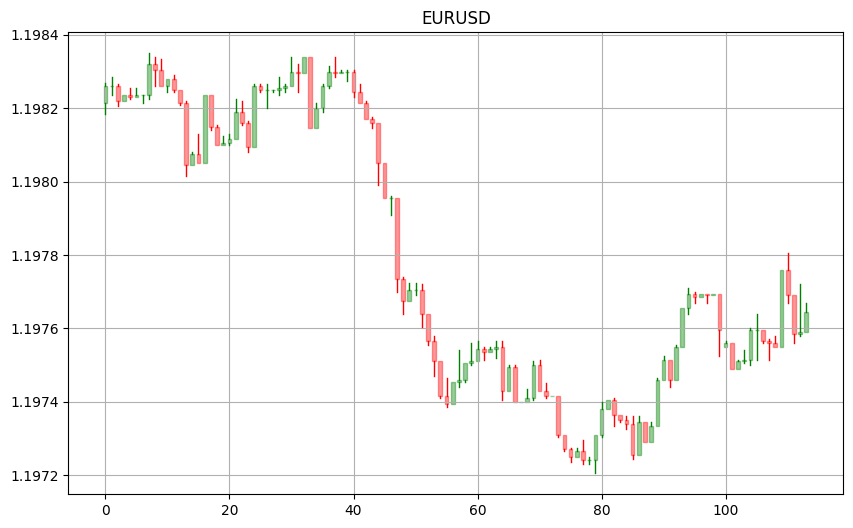

Error 162, reqId 5: Historical Market Data Service error message:API historical data query cancelled: 5


In [217]:
ib = IB()
ib.connect()

In [218]:
contract = Forex('EURUSD')
contract

Forex('EURUSD', exchange='IDEALPRO')

__durationStr__: Time span of all the bars. Examples:
        __'60 S', '30 D', '13 W', '6 M', '10 Y'__.

__barSizeSetting__: Time period of one bar. Must be one of:
        __'1 secs', '5 secs', '10 secs' 15 secs', '30 secs',
        '1 min', '2 mins', '3 mins', '5 mins', '10 mins', '15 mins',
        '20 mins', '30 mins',
        '1 hour', '2 hours', '3 hours', '4 hours', '8 hours',
        '1 day', '1 week', '1 month'__.

In [219]:
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='100 S',
        barSizeSetting='1 secs',
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)

In [224]:
bars

[BarData(date=datetime.datetime(2026, 1, 28, 12, 48, 26, tzinfo=datetime.timezone.utc), open=1.197345, high=1.197345, low=1.197345, close=1.197345, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 28, 12, 48, 27, tzinfo=datetime.timezone.utc), open=1.197345, high=1.197345, low=1.197325, close=1.197335, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 28, 12, 48, 28, tzinfo=datetime.timezone.utc), open=1.197335, high=1.197345, low=1.197335, close=1.197345, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 28, 12, 48, 29, tzinfo=datetime.timezone.utc), open=1.197345, high=1.197345, low=1.19729, close=1.19729, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 28, 12, 48, 30, tzinfo=datetime.timezone.utc), open=1.19729, high=1.19729, low=1.19729, close=1.19729, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 28, 12, 48, 31, tzin

In [156]:
pd.DataFrame(bars)

,date,open,high,low,close,volume,average,barCount
0,2026-01-28 11:50:40+00:00,1.197145,1.197145,1.197110,1.197110,-1.0,-1.0,-1
1,2026-01-28 11:50:50+00:00,1.197110,1.197110,1.197050,1.197050,-1.0,-1.0,-1
2,2026-01-28 11:51:00+00:00,1.197050,1.197205,1.197050,1.197200,-1.0,-1.0,-1
3,2026-01-28 11:51:10+00:00,1.197200,1.197220,1.197200,1.197200,-1.0,-1.0,-1
4,2026-01-28 11:51:20+00:00,1.197200,1.197200,1.197105,1.197105,-1.0,-1.0,-1
5,2026-01-28 11:51:30+00:00,1.197105,1.197150,1.197095,1.197115,-1.0,-1.0,-1
6,2026-01-28 11:51:40+00:00,1.197115,1.197205,1.197090,1.197205,-1.0,-1.0,-1
7,2026-01-28 11:51:50+00:00,1.197205,1.197360,1.197205,1.197350,-1.0,-1.0,-1
8,2026-01-28 11:52:00+00:00,1.197350,1.197460,1.197300,1.197310,-1.0,-1.0,-1
9,2026-01-28 11:52:10+00:00,1.197310,1.197345,1.197290,1.197315,-1.0,-1.0,-1


In [157]:
ib.cancelHistoricalData(bars) # cancel subscription

In [158]:
def onBarUpdate(bars, hasNewBar):  # what shall happen after receiving a new bar
    global df
    df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]]
    df.set_index("date", inplace = True)
    clear_output(wait=True)
    display(df)

In [159]:
# start stream
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='50 S',
        barSizeSetting='5 secs',
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)

In [160]:
bars.updateEvent += onBarUpdate # activate onBarUpdate
ib.sleep(30) # new to be added!!!

True

In [163]:
df # still getting updated until you de-activate or cancel

,open,high,low,close
date,,,,
2026-01-28 11:51:50+00:00,1.197205,1.197305,1.197205,1.197290
2026-01-28 11:51:55+00:00,1.197290,1.197360,1.197290,1.197350
2026-01-28 11:52:00+00:00,1.197350,1.197450,1.197350,1.197445
2026-01-28 11:52:05+00:00,1.197445,1.197460,1.197300,1.197310
2026-01-28 11:52:10+00:00,1.197310,1.197310,1.197290,1.197295
2026-01-28 11:52:15+00:00,1.197295,1.197345,1.197295,1.197315
2026-01-28 11:52:20+00:00,1.197315,1.197315,1.197300,1.197300
2026-01-28 11:52:25+00:00,1.197300,1.197300,1.197220,1.197250
2026-01-28 11:52:30+00:00,1.197250,1.197260,1.197235,1.197250


In [164]:
bars.updateEvent -= onBarUpdate # de-activate onBarUpdate

In [165]:
ib.cancelHistoricalData(bars) # cancel subscription

## Application: Creating a live Candle Stick Chart 

In [225]:
def onBarUpdate(bars, hasNewBar):
    plt.close()
    plot = util.barplot(bars, title = "EURUSD", upColor = "green", downColor = "red")
    clear_output(wait=True)
    display(plot)

In [227]:
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1000 S',
        barSizeSetting='10 secs',
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)

True

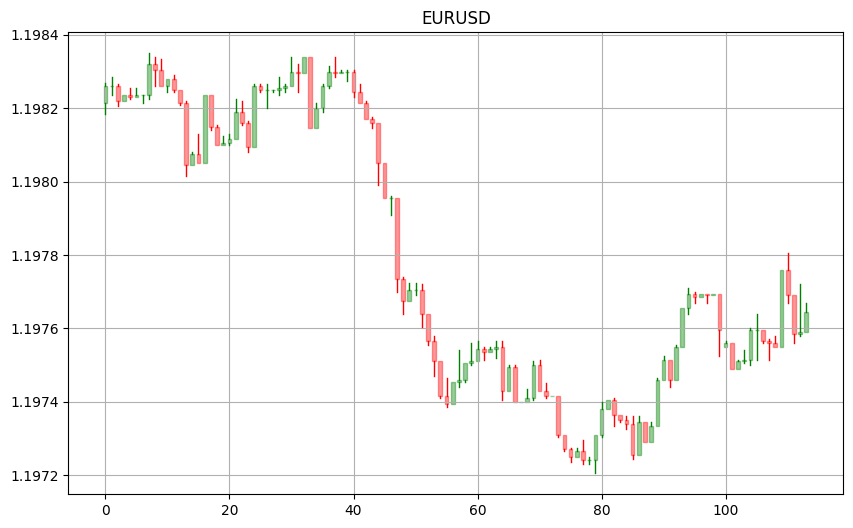

In [229]:
bars.updateEvent += onBarUpdate # activate onBarUpdate
ib.sleep(30) # new to be added!!!

In [239]:
bars.updateEvent -= onBarUpdate # de-activate onBarUpdate

In [240]:
ib.cancelHistoricalData(bars) # cancel subscription

In [243]:
ib.disconnect()

## Preparing the Data for Day Trading

- Problem: most recent bar is (typically) incomplete (until the end of the bar has been reached)
- In Trading: Take actions once a new bar is complete 

In [180]:
from ib_async import * 
import pandas as pd
import numpy as np
import datetime as dt # old
from datetime import datetime, timezone # new
from IPython.display import display, clear_output
util.startLoop() 

In [181]:
ib = IB()
ib.connect()

,open,high,low,close
date,,,,
2026-01-27 22:15:00+00:00,1.203675,1.203745,1.203675,1.203715
2026-01-27 22:16:00+00:00,1.203715,1.203730,1.203705,1.203720
2026-01-27 22:17:00+00:00,1.203720,1.203730,1.203700,1.203715
2026-01-27 22:18:00+00:00,1.203715,1.203775,1.203700,1.203765
2026-01-27 22:19:00+00:00,1.203765,1.203985,1.203765,1.203960
...,...,...,...,...
2026-01-28 12:37:00+00:00,1.198100,1.198260,1.198080,1.198260
2026-01-28 12:38:00+00:00,1.198260,1.198340,1.198200,1.198300
2026-01-28 12:39:00+00:00,1.198300,1.198340,1.198145,1.198300


Error 162, reqId 6: Historical Market Data Service error message:API historical data query cancelled: 6


In [182]:
contract = Forex('EURUSD')
contract

Forex('EURUSD', exchange='IDEALPRO')

In [ ]:
dt.datetime.utcnow() # old

In [183]:
datetime.now(timezone.utc) # new (Python 3.12)

datetime.datetime(2026, 1, 28, 12, 36, 33, 3126, tzinfo=datetime.timezone.utc)

In [184]:
def onBarUpdate(bars, hasNewBar):
    # print(dt.datetime.utcnow()) # old
    print(datetime.now(timezone.utc)) # new (Python 3.12)

In [185]:
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D',
        barSizeSetting='1 min',
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)

In [186]:
bars.updateEvent += onBarUpdate
ib.sleep(30) # new to be added!!!

True

In [187]:
ib.cancelHistoricalData(bars) 

In [188]:
def onBarUpdate(bars, hasNewBar): 
    global df
    df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]].iloc[:-1] # remove current bar (incomplete)
    df.set_index("date", inplace = True)
    clear_output(wait=True)
    display(df)

In [189]:
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D',
        barSizeSetting='1 min',
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)
bars.updateEvent += onBarUpdate 
ib.sleep(90) # new to be added!!!

True

In [190]:
df # still getting updated until you cancel

,open,high,low,close
date,,,,
2026-01-27 22:15:00+00:00,1.203675,1.203745,1.203675,1.203715
2026-01-27 22:16:00+00:00,1.203715,1.203730,1.203705,1.203720
2026-01-27 22:17:00+00:00,1.203720,1.203730,1.203700,1.203715
2026-01-27 22:18:00+00:00,1.203715,1.203775,1.203700,1.203765
2026-01-27 22:19:00+00:00,1.203765,1.203985,1.203765,1.203960
...,...,...,...,...
2026-01-28 12:33:00+00:00,1.198040,1.198285,1.198025,1.198260
2026-01-28 12:34:00+00:00,1.198260,1.198285,1.198205,1.198235
2026-01-28 12:35:00+00:00,1.198235,1.198345,1.198210,1.198215


In [191]:
ib.cancelHistoricalData(bars) 

## Improving Code Efficiency

Idea: We need to run major parts of onBarUpdate only if a bar is complete (== new bar has been added)

In [192]:
bars

[BarData(date=datetime.datetime(2026, 1, 27, 22, 15, tzinfo=datetime.timezone.utc), open=1.203675, high=1.203745, low=1.203675, close=1.203715, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 27, 22, 16, tzinfo=datetime.timezone.utc), open=1.203715, high=1.20373, low=1.203705, close=1.20372, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 27, 22, 17, tzinfo=datetime.timezone.utc), open=1.20372, high=1.20373, low=1.2037, close=1.203715, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 27, 22, 18, tzinfo=datetime.timezone.utc), open=1.203715, high=1.203775, low=1.2037, close=1.203765, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 27, 22, 19, tzinfo=datetime.timezone.utc), open=1.203765, high=1.203985, low=1.203765, close=1.20396, volume=-1.0, average=-1.0, barCount=-1),
 BarData(date=datetime.datetime(2026, 1, 27, 22, 20, tzinfo=datetime.timezone.utc), 

In [202]:
# check if current (incomplete) bar is more recent than the last complete bar
bars[-1].date > bars[-2].date

True

In [194]:
def onBarUpdate(bars, hasNewBar):  
    global df, last_bar
    if bars[-1].date > last_bar: # if bar completed / new bar
        last_bar = bars[-1].date
    
        df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]].iloc[:-1] 
        df.set_index("date", inplace = True)
        clear_output(wait=True)
        display(df)

In [196]:
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D',
        barSizeSetting='1 min',
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)
last_bar = bars[-1].date # initialize last_bar
bars.updateEvent += onBarUpdate
ib.sleep(90) # new to be added!!!

True

In [197]:
df # still getting updated until you cancel

,open,high,low,close
date,,,,
2026-01-27 22:15:00+00:00,1.203675,1.203745,1.203675,1.203715
2026-01-27 22:16:00+00:00,1.203715,1.203730,1.203705,1.203720
2026-01-27 22:17:00+00:00,1.203720,1.203730,1.203700,1.203715
2026-01-27 22:18:00+00:00,1.203715,1.203775,1.203700,1.203765
2026-01-27 22:19:00+00:00,1.203765,1.203985,1.203765,1.203960
...,...,...,...,...
2026-01-28 12:37:00+00:00,1.198100,1.198260,1.198080,1.198260
2026-01-28 12:38:00+00:00,1.198260,1.198340,1.198200,1.198300
2026-01-28 12:39:00+00:00,1.198300,1.198340,1.198145,1.198300


In [198]:
ib.cancelHistoricalData(bars) 

In [199]:
ib.disconnect()

'Disconnecting from 127.0.0.1:7497, 438 B sent in 15 messages, 219 kB received in 658 messages, session time 376 s.'

In [200]:
df

,open,high,low,close
date,,,,
2026-01-27 22:15:00+00:00,1.203675,1.203745,1.203675,1.203715
2026-01-27 22:16:00+00:00,1.203715,1.203730,1.203705,1.203720
2026-01-27 22:17:00+00:00,1.203720,1.203730,1.203700,1.203715
2026-01-27 22:18:00+00:00,1.203715,1.203775,1.203700,1.203765
2026-01-27 22:19:00+00:00,1.203765,1.203985,1.203765,1.203960
...,...,...,...,...
2026-01-28 12:37:00+00:00,1.198100,1.198260,1.198080,1.198260
2026-01-28 12:38:00+00:00,1.198260,1.198340,1.198200,1.198300
2026-01-28 12:39:00+00:00,1.198300,1.198340,1.198145,1.198300


In [201]:
last_bar

datetime.datetime(2026, 1, 28, 12, 42, tzinfo=datetime.timezone.utc)

## Define an SMA Day Trading Strategy

In [203]:
from ib_async import * 
import pandas as pd
import numpy as np
#import datetime as dt
from IPython.display import display, clear_output
util.startLoop() 

In [204]:
ib = IB()
ib.connect()

,close,sma_s,sma_l,position
date,,,,
2026-01-28 01:34:00+00:00,1.199640,1.200863,1.202263,-1
2026-01-28 01:35:00+00:00,1.199580,1.200823,1.202243,-1
2026-01-28 01:36:00+00:00,1.199480,1.200779,1.202221,-1
2026-01-28 01:37:00+00:00,1.199630,1.200743,1.202201,-1
2026-01-28 01:38:00+00:00,1.199425,1.200700,1.202179,-1
...,...,...,...,...
2026-01-28 12:44:00+00:00,1.197400,1.197526,1.197859,-1
2026-01-28 12:45:00+00:00,1.197415,1.197533,1.197856,-1
2026-01-28 12:46:00+00:00,1.197240,1.197537,1.197852,-1


Error 162, reqId 3: Historical Market Data Service error message:API historical data query cancelled: 3


In [205]:
contract = Forex('EURUSD')
contract

Forex('EURUSD', exchange='IDEALPRO')

Strategy: SMA 50/200 (minutes) Crossover (needs to be backtested!!!)

In [206]:
sma_s = 50
sma_l = 200

In [207]:
def onBarUpdate(bars, hasNewBar): 
    global df, last_bar
    
    if bars[-1].date > last_bar: 
        last_bar = bars[-1].date
    
        # Data Processing
        df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]].iloc[:-1]
        df.set_index("date", inplace = True)
        
        ####################### Trading Strategy ###########################
        df = df[["close"]].copy()
        df["sma_s"] = df.close.rolling(sma_s).mean()
        df["sma_l"] = df.close.rolling(sma_l).mean()
        df.dropna(inplace = True)
        df["position"] = np.where(df["sma_s"] > df["sma_l"], 1, -1 )
        ####################################################################
        
        # Action
        clear_output(wait=True)
        display(df)
        

In [208]:
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D',
        barSizeSetting='1 min',
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)
last_bar = bars[-1].date
bars.updateEvent += onBarUpdate 
ib.sleep(120) # new to be added!!!

True

In [209]:
df # still getting updated until you cancel

,close,sma_s,sma_l,position
date,,,,
2026-01-28 01:34:00+00:00,1.199640,1.200863,1.202263,-1
2026-01-28 01:35:00+00:00,1.199580,1.200823,1.202243,-1
2026-01-28 01:36:00+00:00,1.199480,1.200779,1.202221,-1
2026-01-28 01:37:00+00:00,1.199630,1.200743,1.202201,-1
2026-01-28 01:38:00+00:00,1.199425,1.200700,1.202179,-1
...,...,...,...,...
2026-01-28 12:43:00+00:00,1.197545,1.197524,1.197863,-1
2026-01-28 12:44:00+00:00,1.197400,1.197526,1.197859,-1
2026-01-28 12:45:00+00:00,1.197415,1.197533,1.197856,-1


In [210]:
ib.cancelHistoricalData(bars) 

In [211]:
ib.disconnect()

'Disconnecting from 127.0.0.1:7497, 200 B sent in 10 messages, 70.1 kB received in 483 messages, session time 184 s.'

## Trading

__Please run the following code only with your Paper Trading Account!!!__

__Check the Regular Trading Hours!!!__

In [244]:
from ib_async import * 
import pandas as pd
import numpy as np
#import datetime as dt
from IPython.display import display, clear_output
util.startLoop() 

In [ ]:
ib = IB()
ib.connect()

,close,sma_s,sma_l,position
date,,,,
2026-01-28 01:34:00+00:00,1.199640,1.200863,1.202263,-1
2026-01-28 01:35:00+00:00,1.199580,1.200823,1.202243,-1
2026-01-28 01:36:00+00:00,1.199480,1.200779,1.202221,-1
2026-01-28 01:37:00+00:00,1.199630,1.200743,1.202201,-1
2026-01-28 01:38:00+00:00,1.199425,1.200700,1.202179,-1
...,...,...,...,...
2026-01-28 13:02:00+00:00,1.197745,1.197779,1.197772,1
2026-01-28 13:03:00+00:00,1.197690,1.197786,1.197769,1
2026-01-28 13:04:00+00:00,1.197695,1.197794,1.197766,1


Error 162, reqId 5: Historical Market Data Service error message:API historical data query cancelled: 5


In [246]:
# strategy parameters
sma_s = 50
sma_l = 200
freq = "1 min"
units = 1000
contract = Forex('EURUSD') # for data streaming
ib.qualifyContracts(contract)
cfd = CFD("EUR", currency = "USD") # for trading
ib.qualifyContracts(cfd)
conID = cfd.conId

In [ ]:
conID

__barSizeSetting__: Time period of one bar. Must be one of:
        __'1 secs', '5 secs', '10 secs' 15 secs', '30 secs',
        '1 min', '2 mins', '3 mins', '5 mins', '10 mins', '15 mins',
        '20 mins', '30 mins',
        '1 hour', '2 hours', '3 hours', '4 hours', '8 hours',
        '1 day', '1 week', '1 month'__.

In [247]:
def onBarUpdate(bars, hasNewBar):  
    global df, last_bar
    
    if bars[-1].date > last_bar: 
        last_bar = bars[-1].date
    
        # Data Processing
        df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]].iloc[:-1] 
        df.set_index("date", inplace = True)
        
        ####################### Trading Strategy ###########################
        df = df[["close"]].copy()
        df["sma_s"] = df.close.rolling(sma_s).mean()
        df["sma_l"] = df.close.rolling(sma_l).mean()
        df.dropna(inplace = True)
        df["position"] = np.where(df["sma_s"] > df["sma_l"], 1, -1 )
        ####################################################################
        
        # Trading
        target = df["position"][-1] * units
        execute_trade(target = target)
        
        # Display
        clear_output(wait=True)
        display(df)
    else:
        pass

def execute_trade(target):
    global current_pos
    
    # 1. get current Position
    try:
        current_pos = [pos.position for pos in ib.positions() if pos.contract.conId == conID][0]
    except:
        current_pos = 0
         
    # 2. identify required trades
    trades = target - current_pos
        
    # 3. trade execution
    if trades > 0:
        side = "BUY"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)  
    elif trades < 0:
        side = "SELL"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)
    else:
        pass

In [248]:
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D', # must be sufficiently long!!! (200 * 1 min)
        barSizeSetting=freq,
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)
last_bar = bars[-1].date
bars.updateEvent += onBarUpdate
ib.sleep(240) # new - to be added

True

In [ ]:
### remember: Trading continues until you cancel!!!

In [249]:
ib.cancelHistoricalData(bars)  # cancel trading

In [250]:
df

,close,sma_s,sma_l,position
date,,,,
2026-01-28 01:34:00+00:00,1.199640,1.200863,1.202263,-1
2026-01-28 01:35:00+00:00,1.199580,1.200823,1.202243,-1
2026-01-28 01:36:00+00:00,1.199480,1.200779,1.202221,-1
2026-01-28 01:37:00+00:00,1.199630,1.200743,1.202201,-1
2026-01-28 01:38:00+00:00,1.199425,1.200700,1.202179,-1
...,...,...,...,...
2026-01-28 13:02:00+00:00,1.197745,1.197779,1.197772,1
2026-01-28 13:03:00+00:00,1.197690,1.197786,1.197769,1
2026-01-28 13:04:00+00:00,1.197695,1.197794,1.197766,1


In [251]:
ib.disconnect()

'Disconnecting from 127.0.0.1:7497, 727 B sent in 14 messages, 111 kB received in 1169 messages, session time 548 s.'

## Trade Reporting

In [ ]:
from ib_async import * 
import pandas as pd
import numpy as np
#import datetime as dt
from datetime import datetime, timezone # new
from IPython.display import display, clear_output
util.startLoop()

In [ ]:
ib = IB()
ib.connect()

In [ ]:
ib.fills()

In [ ]:
util.df([fs.execution for fs in ib.fills()])[["execId", "time", "side", "cumQty", "avgPrice"]].set_index("execId")

In [ ]:
util.df([fs.commissionReport for fs in ib.fills()])[["execId", "realizedPNL"]].set_index("execId")

In [ ]:
# strategy parameters
sma_s = 2
sma_l = 5
freq = "1 min"
units = 1000
contract = Forex('EURUSD') 
ib.qualifyContracts(contract)
cfd = CFD("EUR", currency = "USD")
ib.qualifyContracts(cfd)
conID = cfd.conId

In [ ]:
def onBarUpdate(bars, hasNewBar):  
    global df, last_bar
    
    if bars[-1].date > last_bar: 
        last_bar = bars[-1].date
    
        # Data Processing
        df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]].iloc[:-1] 
        df.set_index("date", inplace = True)
        
        ####################### Trading Strategy ###########################
        df = df[["close"]].copy()
        df["sma_s"] = df.close.rolling(sma_s).mean()
        df["sma_l"] = df.close.rolling(sma_l).mean()
        df.dropna(inplace = True)
        df["position"] = np.where(df["sma_s"] > df["sma_l"], 1, -1 )
        ####################################################################
        
        # Trading
        target = df["position"][-1] * units
        execute_trade(target = target)
        
        # Display
        clear_output(wait=True)
        display(df)
    else:
        try:
            trade_reporting()
        except:
            pass

def execute_trade(target):
    global current_pos
    
    # 1. get current Position
    try:
        current_pos = [pos.position for pos in ib.positions() if pos.contract.conId == conID][0]
    except:
        current_pos = 0
         
    # 2. identify required trades
    trades = target - current_pos
        
    # 3. trade execution
    if trades > 0:
        side = "BUY"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)  
    elif trades < 0:
        side = "SELL"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)
    else:
        pass

def trade_reporting():
    global report
    
    fill_df = util.df([fs.execution for fs in ib.fills()])[["execId", "time", "side", "cumQty", "avgPrice"]].set_index("execId")
    profit_df = util.df([fs.commissionReport for fs in ib.fills()])[["execId", "realizedPNL"]].set_index("execId")
    report = pd.concat([fill_df, profit_df], axis = 1).set_index("time").loc[session_start:]
    report = report.groupby("time").agg({"side":"first", "cumQty":"max", "avgPrice":"mean", "realizedPNL":"sum"})
    report["cumPNL"] = report.realizedPNL.cumsum()
        
    clear_output(wait=True)
    display(df, report)

In [ ]:
# session_start = pd.to_datetime(dt.datetime.utcnow()).tz_localize("utc") # old
session_start = pd.to_datetime(datetime.now(timezone.utc))# new 
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D',
        barSizeSetting=freq,
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)
last_bar = bars[-1].date
bars.updateEvent += onBarUpdate
ib.sleep(120) # new - to be added

In [ ]:
df # still getting updated until you cancel. Trading continues until you cancel!!!

In [ ]:
report # still getting updated until you cancel. Trading continues until you cancel!!!

In [ ]:
ib.cancelHistoricalData(bars) # cancel trading

In [ ]:
ib.disconnect()

## Stop the Trading Session

Potential Triggers:
- stop at a certain time (e.g. 21:59 UTC time)
- stop once a certain profit/loss limit has been reached
- etc.

Required Actions:
- Stop Stream/Session
- Close Open Position (go neutral)

In [ ]:
from ib_async import * 
import pandas as pd
import numpy as np
import datetime as dt
from datetime import datetime, timezone # new
from IPython.display import display, clear_output
util.startLoop()

In [ ]:
ib = IB()
ib.connect()

In [ ]:
# strategy parameters
sma_s = 2
sma_l = 5
freq = "1 min"
units = 1000
end_time = dt.time(11, 5, 0) # stop condition
contract = Forex('EURUSD') 
ib.qualifyContracts(contract)
cfd = CFD("EUR", currency = "USD")
ib.qualifyContracts(cfd)
conID = cfd.conId

In [ ]:
# dt.datetime.utcnow().time() #old

In [ ]:
datetime.now(timezone.utc).time() # new

In [ ]:
datetime.now(timezone.utc).time() >= end_time # new

In [ ]:
def onBarUpdate(bars, hasNewBar):  
    global df, last_bar
    
    if bars[-1].date > last_bar: 
        last_bar = bars[-1].date
    
        # Data Processing
        df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]].iloc[:-1] 
        df.set_index("date", inplace = True)
        
        ####################### Trading Strategy ###########################
        df = df[["close"]].copy()
        df["sma_s"] = df.close.rolling(sma_s).mean()
        df["sma_l"] = df.close.rolling(sma_l).mean()
        df.dropna(inplace = True)
        df["position"] = np.where(df["sma_s"] > df["sma_l"], 1, -1 )
        ####################################################################
        
        # Trading
        target = df["position"][-1] * units
        execute_trade(target = target)
        
        # Display
        clear_output(wait=True)
        display(df)
    else:
        try:
            trade_reporting()
        except:
            pass

def execute_trade(target):
    global current_pos
    
    # 1. get current Position
    try:
        current_pos = [pos.position for pos in ib.positions() if pos.contract.conId == conID][0]
    except:
        current_pos = 0
         
    # 2. identify required trades
    trades = target - current_pos
        
    # 3. trade execution
    if trades > 0:
        side = "BUY"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)  
    elif trades < 0:
        side = "SELL"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)
    else:
        pass

def trade_reporting():
    global report
    
    fill_df = util.df([fs.execution for fs in ib.fills()])[["execId", "time", "side", "cumQty", "avgPrice"]].set_index("execId")
    profit_df = util.df([fs.commissionReport for fs in ib.fills()])[["execId", "realizedPNL"]].set_index("execId")
    report = pd.concat([fill_df, profit_df], axis = 1).set_index("time").loc[session_start:]
    report = report.groupby("time").agg({"side":"first", "cumQty":"max", "avgPrice":"mean", "realizedPNL":"sum"})
    report["cumPNL"] = report.realizedPNL.cumsum()
        
    clear_output(wait=True)
    display(df, report)
  

In [ ]:
# start trading session
session_start = pd.to_datetime(datetime.now(timezone.utc))# new
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D',
        barSizeSetting=freq,
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)
last_bar = bars[-1].date
bars.updateEvent += onBarUpdate
ib.sleep(30) # new - to be added (optional)

# stop trading session
while True:
    ib.sleep(5) # check every 5 seconds
    if datetime.now(timezone.utc).time() >= end_time: # if stop conditions has been met
        execute_trade(target = 0) # close open position 
        ib.cancelHistoricalData(bars) # stop stream
        ib.sleep(10)
        try:
            trade_reporting() # final reporting
        except:
            pass
        print("Session Stopped.")
        ib.disconnect()
        break
    else:
        pass

## Trading other Strategies - Coding Challenge

In [ ]:
from ib_async import * 
import pandas as pd
import numpy as np
import datetime as dt
from datetime import datetime, timezone # new
from IPython.display import display, clear_output
util.startLoop()

In [ ]:
ib = IB()
ib.connect()

__Strategy 1__: Simple Contrarian Strategy (1min / window = 1)

## Stop here if you don´t want to see the solution!

###############################################################

In [ ]:
# strategy parameters
freq = "1 min"
window = 1
units = 1000
end_time = dt.time(21, 59, 0) # stop condition
contract = Forex('EURUSD') 
ib.qualifyContracts(contract)
cfd = CFD("EUR", currency = "USD")
ib.qualifyContracts(cfd)
conID = cfd.conId

In [ ]:
def onBarUpdate(bars, hasNewBar):  
    global df, last_bar
    
    if bars[-1].date > last_bar: 
        last_bar = bars[-1].date
    
        # Data Processing
        df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]].iloc[:-1] 
        df.set_index("date", inplace = True)
        
        ####################### Trading Strategy ###########################
        df = df[["close"]].copy()
        df["returns"] = np.log(df["close"] / df["close"].shift())
        df["position"] = -np.sign(df.returns.rolling(window).mean())
        ####################################################################
        
        # Trading
        target = df["position"][-1] * units
        execute_trade(target = target)
        
        # Display
        clear_output(wait=True)
        display(df)
    else:
        try:
            trade_reporting()
        except:
            pass

def execute_trade(target):
    global current_pos
    
    # 1. get current Position
    try:
        current_pos = [pos.position for pos in ib.positions() if pos.contract.conId == conID][0]
    except:
        current_pos = 0
         
    # 2. identify required trades
    trades = target - current_pos
        
    # 3. trade execution
    if trades > 0:
        side = "BUY"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)  
    elif trades < 0:
        side = "SELL"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)
    else:
        pass

def trade_reporting():
    global report
    
    fill_df = util.df([fs.execution for fs in ib.fills()])[["execId", "time", "side", "cumQty", "avgPrice"]].set_index("execId")
    profit_df = util.df([fs.commissionReport for fs in ib.fills()])[["execId", "realizedPNL"]].set_index("execId")
    report = pd.concat([fill_df, profit_df], axis = 1).set_index("time").loc[session_start:]
    report = report.groupby("time").agg({"side":"first", "cumQty":"max", "avgPrice":"mean", "realizedPNL":"sum"})
    report["cumPNL"] = report.realizedPNL.cumsum()
        
    clear_output(wait=True)
    display(df, report)
  

In [ ]:
# start trading session
session_start = pd.to_datetime(datetime.now(timezone.utc))# new
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D',
        barSizeSetting=freq,
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)
last_bar = bars[-1].date
bars.updateEvent += onBarUpdate
ib.sleep(30) # new - to be added (optional)

# stop trading session
while True:
    ib.sleep(5) # check every 5 seconds
    if datetime.now(timezone.utc).time() >= end_time: # if stop conditions has been met
        execute_trade(target = 0) # close open position 
        ib.cancelHistoricalData(bars) # stop stream
        ib.sleep(10)
        try:
            trade_reporting() # final reporting
        except:
            pass
        print("Session Stopped.")
        ib.disconnect()
        break
    else:
        pass

__Strategy 2__: Bollinger Bands SMA 20 (minutes) / 1 Standard Deviation

## Stop here if you don´t want to see the solution!

###############################################################

In [ ]:
from ib_async import * 
import pandas as pd
import numpy as np
import datetime as dt
from datetime import datetime, timezone # new
from IPython.display import display, clear_output
util.startLoop()

In [ ]:
ib = IB()
ib.connect()

In [ ]:
# strategy parameters
freq = "1 min"
sma = 20
dev = 1
units = 1000
end_time = dt.time(21, 59, 0) # stop condition
contract = Forex('EURUSD') 
ib.qualifyContracts(contract)
cfd = CFD("EUR", currency = "USD")
ib.qualifyContracts(cfd)
conID = cfd.conId

In [ ]:
def onBarUpdate(bars, hasNewBar):  
    global df, last_bar
    
    if bars[-1].date > last_bar: 
        last_bar = bars[-1].date
    
        # Data Processing
        df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]].iloc[:-1] 
        df.set_index("date", inplace = True)
        
        ####################### Trading Strategy ###########################
        df = df[["close"]].copy()
        df["SMA"] = df["close"].rolling(sma).mean()
        df["Lower"] = df["SMA"] - df["close"].rolling(sma).std() * dev
        df["Upper"] = df["SMA"] + df["close"].rolling(sma).std() * dev
        df["distance"] = df["close"] - df.SMA
        df["position"] = np.where(df["close"] < df.Lower, 1, np.nan)
        df["position"] = np.where(df["close"] > df.Upper, -1, df["position"])
        df["position"] = np.where(df.distance * df.distance.shift(1) < 0, 0, df["position"])
        df["position"] = df.position.ffill().fillna(0)
        ####################################################################
        
        # Trading
        target = df["position"][-1] * units
        execute_trade(target = target)
        
        # Display
        clear_output(wait=True)
        display(df)
    else:
        try:
            trade_reporting()
        except:
            pass

def execute_trade(target):
    global current_pos
    
    # 1. get current Position
    try:
        current_pos = [pos.position for pos in ib.positions() if pos.contract.conId == conID][0]
    except:
        current_pos = 0
         
    # 2. identify required trades
    trades = target - current_pos
        
    # 3. trade execution
    if trades > 0:
        side = "BUY"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)  
    elif trades < 0:
        side = "SELL"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)
    else:
        pass

def trade_reporting():
    global report
    
    fill_df = util.df([fs.execution for fs in ib.fills()])[["execId", "time", "side", "cumQty", "avgPrice"]].set_index("execId")
    profit_df = util.df([fs.commissionReport for fs in ib.fills()])[["execId", "realizedPNL"]].set_index("execId")
    report = pd.concat([fill_df, profit_df], axis = 1).set_index("time").loc[session_start:]
    report = report.groupby("time").agg({"side":"first", "cumQty":"max", "avgPrice":"mean", "realizedPNL":"sum"})
    report["cumPNL"] = report.realizedPNL.cumsum()
        
    clear_output(wait=True)
    display(df, report)
  

In [ ]:
# start trading session
session_start = pd.to_datetime(datetime.now(timezone.utc))# new
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D',
        barSizeSetting=freq,
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)
last_bar = bars[-1].date
bars.updateEvent += onBarUpdate
ib.sleep(30) # new - to be added (optional)

# stop trading session
while True:
    ib.sleep(5) # check every 5 seconds
    if datetime.now(timezone.utc).time() >= end_time: # if stop conditions has been met
        execute_trade(target = 0) # close open position 
        ib.cancelHistoricalData(bars) # stop stream
        ib.sleep(10)
        try:
            trade_reporting() # final reporting
        except:
            pass
        print("Session Stopped.")
        ib.disconnect()
        break
    else:
        pass

## Machine Learning Strategies (1) - Model Fitting

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier # added (from sklearn v. 1.7)

In [ ]:
data = pd.read_csv("five_minute.csv", parse_dates = ["time"], index_col = "time")
data

In [ ]:
data["returns"] = np.log(data.div(data.shift(1)))

In [ ]:
data.dropna(inplace = True)

In [ ]:
data["direction"] = np.sign(data.returns)
data

In [ ]:
lags = 2

In [ ]:
cols = []
for lag in range(1, lags + 1):
    col = "lag{}".format(lag)
    data[col] = data.returns.shift(lag)
    cols.append(col)
data.dropna(inplace = True)

++++++++++++++++++++++++++++

__Scaling/Standardizing Features (new)__

In [ ]:
means = data[cols].mean()
means

In [ ]:
stand_devs = data[cols].std()
stand_devs

In [ ]:
data[cols] = (data[cols]-means) / stand_devs
data

+++++++++++++++++++++++++++

In [ ]:
lm = OneVsRestClassifier(LogisticRegression(C = 1e6, max_iter = 100000)) # new (from sklearn v. 1.7)

In [ ]:
lm.fit(data[cols], data.direction)
lm

__In-Sample "Prediction"__

In [ ]:
data["pred"] = lm.predict(data[cols])
data

In [ ]:
hits = np.sign(data.direction * data.pred).value_counts()
hits

In [ ]:
hit_ratio = hits[1.0] / sum(hits)
hit_ratio

__Saving the model__

In [ ]:
lm

In [ ]:
import pickle

In [ ]:
pickle.dump(lm, open("logreg.pkl", "wb"))

__Saving the parameters (mean, std)__ NEW

In [ ]:
params = {"mu":means, "std":stand_devs}
params

In [ ]:
pickle.dump(params, open("params.pkl", "wb"))

## Machine Learning Strategies (2) - Implementation

In [ ]:
from ib_async import * 
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
import pickle
import datetime as dt
from datetime import datetime, timezone # new
from IPython.display import display, clear_output
util.startLoop()

In [ ]:
ib = IB()
ib.connect()

In [ ]:
# strategy parameters
freq = "5 mins"
lm = pickle.load(open("logreg.pkl", "rb"))
lags = 2
params = pickle.load(open("params.pkl", "rb"))
means = params["mu"]
stand_devs = params["std"]
units = 1000
end_time = dt.time(21, 59, 0) # stop condition
contract = Forex('EURUSD') 
ib.qualifyContracts(contract)
cfd = CFD("EUR", currency = "USD")
ib.qualifyContracts(cfd)
conID = cfd.conId

In [ ]:
lm

In [ ]:
def onBarUpdate(bars, hasNewBar):  
    global df, last_bar
    
    if bars[-1].date > last_bar: 
        last_bar = bars[-1].date
    
        # Data Processing
        df = pd.DataFrame(bars)[["date", "open", "high", "low", "close"]]#.iloc[:-1] keep latest incomplete bar
        df.set_index("date", inplace = True)
        
        ####################### Trading Strategy ###########################
        df = df[["close"]].copy()
        df["returns"] = np.log(df["close"] / df["close"].shift())

        cols = []
        for lag in range(1, lags + 1):
            col = "lag{}".format(lag)
            df[col] = df.returns.shift(lag)
            cols.append(col)
        df.dropna(inplace = True)
        df[cols] = (df[cols] - means) / stand_devs
        
        df["position"] = lm.predict(df[cols])
        ####################################################################
        
        # Trading
        target = df["position"][-1] * units
        execute_trade(target = target)
        
        # Display
        clear_output(wait=True)
        display(df)
    else:
        try:
            trade_reporting()
        except:
            pass

def execute_trade(target):
    global current_pos
    
    # 1. get current Position
    try:
        current_pos = [pos.position for pos in ib.positions() if pos.contract.conId == conID][0]
    except:
        current_pos = 0
         
    # 2. identify required trades
    trades = target - current_pos
        
    # 3. trade execution
    if trades > 0:
        side = "BUY"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)  
    elif trades < 0:
        side = "SELL"
        order = MarketOrder(side, abs(trades))
        trade = ib.placeOrder(cfd, order)
    else:
        pass

def trade_reporting():
    global report
    
    fill_df = util.df([fs.execution for fs in ib.fills()])[["execId", "time", "side", "cumQty", "avgPrice"]].set_index("execId")
    profit_df = util.df([fs.commissionReport for fs in ib.fills()])[["execId", "realizedPNL"]].set_index("execId")
    report = pd.concat([fill_df, profit_df], axis = 1).set_index("time").loc[session_start:]
    report = report.groupby("time").agg({"side":"first", "cumQty":"max", "avgPrice":"mean", "realizedPNL":"sum"})
    report["cumPNL"] = report.realizedPNL.cumsum()
        
    clear_output(wait=True)
    display(df, report)

In [ ]:
# start trading session
session_start = pd.to_datetime(datetime.now(timezone.utc))# new
bars = ib.reqHistoricalData(
        contract,
        endDateTime='',
        durationStr='1 D',
        barSizeSetting=freq,
        whatToShow='MIDPOINT',
        useRTH=True,
        formatDate=2,
        keepUpToDate=True)
last_bar = bars[-1].date
bars.updateEvent += onBarUpdate
ib.sleep(30) # new - to be added (optional)

# stop trading session
while True:
    ib.sleep(5) # check every 5 seconds
    if datetime.now(timezone.utc).time() >= end_time: # if stop conditions has been met
        execute_trade(target = 0) # close open position 
        ib.cancelHistoricalData(bars) # stop stream
        ib.sleep(10)
        try:
            trade_reporting() # final reporting
        except:
            pass
        print("Session Stopped.")
        ib.disconnect()
        break
    else:
        pass